<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/Lab05/pmp_lab5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Exerciţiu laborator 5**
**Modele Markov ascunse**

Un profesor dă teste care pot fi dificile, medii sau uşoare. Probabilitatea dificultăţii primului test este aceeaşi.

Dacă, la un moment dat, dă un test dificil, următorul test poate fi doar mediu sau uşor, cu aceeaşi probabilitate. Însă dacă dă un test mediu sau uşor, atunci următorul test va fi dificil cu probabilitate 0.5, sau mediu sau uşor cu aceeaşi probabilitate, 0.25.

Nota unui student la test, FB, B, S sau NS depinde de dificultatea testului. Astfel, probabilităţile condiţionate ale notei obţinute, dată fiind dificultatea testului, sunt:
*    test dificil: [0.1, 0.2, 0.4, 0.3];
*    test mediu: [0.15, 0.25, 0.5, 0.1];
*    test uşor: [0.2, 0.3, 0.4, 0.1].

**a)** Utilizaţi librăria hmmlearn pentru a defini modelul Markov ascuns şi desenaţi diagrama de stare.

**b)** Să presupunem că aţi observat următoarea secvenţă de note: FB, FB, S, B, B, S, B, B, NS, B, B, S. Determinaţi cea mai probabilă secvenţă de dificultăţi pentru testele corespunzaătoare şi probabilitatea acesteia.

In [ ]:
!pip install -q hmmlearn graphviz

In [ ]:
import numpy as np
import graphviz
from hmmlearn import hmm

In [ ]:
# a)

stari = ["dificil", "mediu", "usor"]
observatii = ["FB", "B", "S", "NS"]

pi = np.array([1/3, 1/3, 1/3])

A = np.array([
    [0.0,  0.5,  0.5 ],
    [0.5,  0.25, 0.25],
    [0.5,  0.25, 0.25],
])

B = np.array([
    #  FB    B     S     NS
    [0.10, 0.20, 0.40, 0.30],
    [0.15, 0.25, 0.50, 0.10],
    [0.20, 0.30, 0.40, 0.10],
])

model = hmm.CategoricalHMM(n_components=3, init_params="")
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

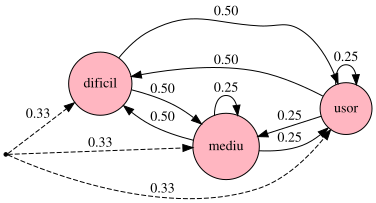

In [ ]:
dot = graphviz.Digraph()
dot.attr(rankdir="LR")
dot.node("Start", shape="point")
for s in stari:
    dot.node(s, shape="circle", style="filled", fillcolor="lightpink")
for i, s in enumerate(stari):
    dot.edge("Start", s, label=f"{pi[i]:.2f}", style="dashed")
for i, a in enumerate(stari):
    for j, b in enumerate(stari):
        if A[i, j] > 0:
            dot.edge(a, b, label=f"{A[i, j]:.2f}")
dot

In [ ]:
# b)

secventa = ["FB", "FB", "S", "B", "B", "S", "B", "B", "NS", "B", "B", "S"]
obs = np.array([observatii.index(o) for o in secventa]).reshape(-1, 1)

log_prob, drum = model.decode(obs)

print([stari[s] for s in drum])
print("P =", np.exp(log_prob))

['usor', 'usor', 'dificil', 'usor', 'dificil', 'mediu', 'dificil', 'usor', 'dificil', 'usor', 'dificil', 'mediu']
P = 2.109375000000024e-11
